# Graphs

_By Linden Disney-Hogg_

In the following notebooks, we will delve into the topic of graph neural networks. But to do so, we first have to understand the data that GNNs deal with. So, what are graphs?

Here, we will cover some of the basics, including essential terminology and Python toolkits. For an easy-to-read deep dive into graph theory, I recommend the book [Introduction to Graph Theory by Robin J. Wilson](https://webhomes.maths.ed.ac.uk/~v1ranick/papers/wilsongraph.pdf).

The essential Python library needed for dealing with graph data is [`networkx`](https://networkx.org/). You can find more [tutorials](https://networkx.org/documentation/stable/tutorial.html) on their homepage.

Before getting going let's make an incomplete list of areas where graphs arise in the 'real' world (can you think of how they appear in your field):


*   logistics (route planning)
*   social networks (identifying cliques, influence)
*   computer science (page ranking, traffic routing, dependency graphs)
*   chemistry (compund structure identification, e.g. alkanes as trees)
*   biology (DNA and protein structure)
*   mathematics (simplicial complexes, dynkin diagrams, tropical curves)
*   linguistics (semantic networks, e.g. for bias analysis)
*   physics (Feynmann diagrams)


I asked ChatGPT to read everyone's research expertise and describe how graph theory applies to their work, perhaps you are included and did not expect it? See the appendix for that output.


As they have been a subject of intense study over many centuries, there are often exceptionally efficient algorithms for computing with graphs: if you can frame a problem you have as a graph problem, you will likely have luck in solving it (at least heuristically) rather efficiently.


As a first example, let's look at the famous problem which kicked off the study of graph theory in 1736: the [Königsberg bridge problem](https://networkx.org/nx-guides/content/algorithms/euler/euler.html#seven-bridges-of-konigsberg). Looking at the map below, can we visit every part of the town crossing each bridge exactly once? Euler turned the problem into one in graph theory, and proved that such a path exists iff the degree of each vertex in the graph is even. We will define these terms and more soon, but first we just use `networkx` to construct and view the graph.

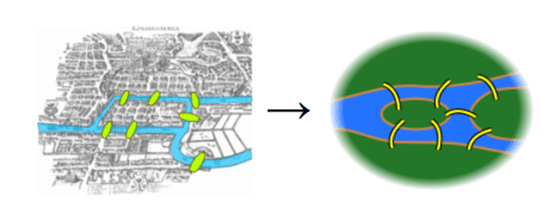

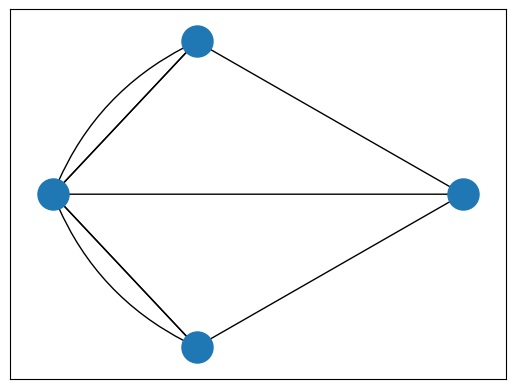

In [ ]:
# Minimal inputs
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

# Construct the graph.
# We will construct using the adjacency matrix, which we shall described in a
# minute.
# Note this is technical a MultiGraph, rather than just a Graph.
adj_array = np.array([[0, 2, 1, 0],
                      [2, 0, 1, 2],
                      [1, 1, 0, 1],
                      [0, 2, 1, 0]])
G = nx.from_numpy_array(adj_array,
                        create_using=nx.MultiGraph,
                        parallel_edges=True)

# Draw the graph.
# Do not focus for now on how this was done, as it is just an  implementation
# technicality.
# Only note that this is not an invariant description, it required a choice of
# where the nodes and edges were placed. This will be relevant later when
# thinking about graph isomorphism.
positions = [(0.7, 1), (0, 0), (2, 0), (0.7, -1)]
nx.draw_networkx_nodes(G, pos=positions, node_size=500)
nx.draw_networkx_edges(
    G, pos=positions)
nx.draw_networkx_edges(
    G, pos=positions,
    edgelist=[(0, 1), (1, 3)],
    connectionstyle="arc3,rad=0.2")

plt.show()

## Basic definitions

At it's simplest, a graph $G$ is a set of _vertices_ (also called _nodes_) $V$ and edges between these vertices $E$. We visualise them as above, with vertices represented by a point, and edges represented as lines between points.

In [ ]:
# Networkx uses the term nodes
G.nodes(), G.edges()

(NodeView((0, 1, 2, 3)),
 MultiEdgeDataView([(0, 1), (0, 1), (0, 2), (1, 2), (1, 3), (1, 3), (2, 3)]))

Note how in the above each vertex gets a label $v$ (here the nonnegative integers) and an edge gets a label $(v, w)$ where $v,w$ are labels of the vertices joined by an edge. In an _undirected graph_ we do not care about the ordering of the vertex labels in an edge, but in a _directed graph_ (or _digraph_). A graph is _simple_ if it has at most a single edge between any pair of vertices and it has no _loops_ (edges from a vertex to iself). `networkx` calls a graph that is not simple a _MultiGraph_. We can also decorate edges with any dictionary of attributes: most commonly one assigns a _weight_ (more later).

We can also define the _degree_ of a vertex to be the number of edges incident to it (for a directed graph one can talk of the _in degree_ and _out degree_).

In [ ]:
G.degree
# We see the degree of *all* of these vertices is odd, so there is no solution
# to the Konigsberg bridge problem.

MultiDegreeView({0: 3, 1: 5, 2: 3, 3: 3})

You can look at the [`networkx` MultiGraph class](https://networkx.org/documentation/stable/reference/classes/multigraph.html) to get a sense of what basic properties are available.

## Representations of graphs

We have already seen one representation of a graph, its _adjacency matrix_ $A = A(G)$. For a multidigraph, choosing an ordering of the vertices the entry $A_{ij}$ is the number of edges $i \to j$.

In [ ]:
# convert_matrix is a nx modlule for converting graphs to common data
# containers.
A = nx.convert_matrix.to_numpy_array(G)
A

array([[0., 2., 1., 0.],
       [2., 0., 1., 2.],
       [1., 1., 0., 1.],
       [0., 2., 1., 0.]])

Clearly if $G$ is a simple undirected graph then $A$ is a
symmetric binary matrix with zeros on the diagonal. In this case the adjacency matrix is an inefficient way to store the information of the graph $G$. Moreover, if a graph is _sparse_, that is many entries of adjacency matrix are zero, then this representation is even more inefficient.


That said, with simple undirected graphs the adjacency matrix allows us to perform some magic, for example
$$
(A^l)_{ij} = \lvert \text{length-$l$ paths from $i$ to $j$} \rvert.
$$

An obvious point to make is that the choice of ordering of the vertices affects $A$, and permutating the vertices corresponds to conjugating $A$ by the associated [permutation matrix](https://en.wikipedia.org/wiki/Permutation_matrix).

We can also describe graphs as ["dicts of dicts of dicts"](https://networkx.org/documentation/stable/reference/introduction.html#data-structure) which is more efficient for large sparse networks. The keys are the vertices (which can thus be given any hashable label), and the corresponding values are themselves dictionaries describing the adjacency data of the vertex (i.e. what it shares an edge with and properties of that edge). Multigraphs go one depth of dictionary further.

In [ ]:
G_dict = nx.to_dict_of_dicts(G)
# Look at the full structure, keyed by vertices
print(G_dict)
# G_dict[0] contains information of all vertices adjacent to 0,
print(G_dict[0])
# G_dict[0][1] contains information of all edges between 0 and 1,
print(G_dict[0][1])
# G_dict[0][1][0] gives the attributes of the first edge between 0 and 1
print(G_dict[0][1][0])

{0: {1: {0: {'weight': 1}, 1: {'weight': 1}}, 2: {0: {'weight': 1}}}, 1: {0: {0: {'weight': 1}, 1: {'weight': 1}}, 2: {0: {'weight': 1}}, 3: {0: {'weight': 1}, 1: {'weight': 1}}}, 2: {0: {0: {'weight': 1}}, 1: {0: {'weight': 1}}, 3: {0: {'weight': 1}}}, 3: {1: {0: {'weight': 1}, 1: {'weight': 1}}, 2: {0: {'weight': 1}}}}
{1: {0: {'weight': 1}, 1: {'weight': 1}}, 2: {0: {'weight': 1}}}
{0: {'weight': 1}, 1: {'weight': 1}}
{'weight': 1}


*Aside:* when learning about GNNs and the WL test one will see that an adjacency dict is very helpful.

## Structures of graphs

A _subgraph_ of $G$ is a graph whose vertices and edges all belong to $G$.

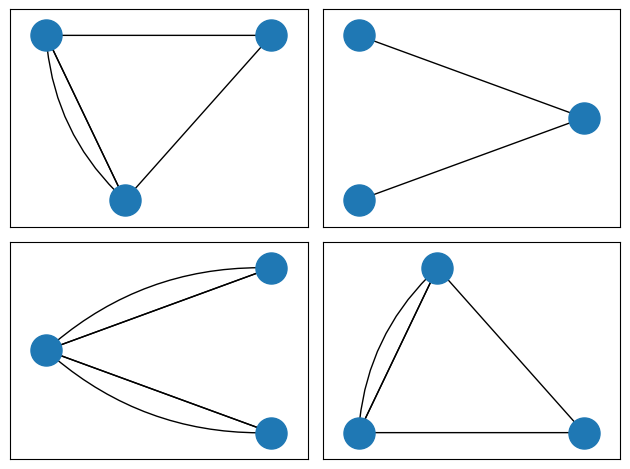

In [ ]:
# We take all the subgraphs of G obtained by removing a single vertex.
# This is called the _deck_ or a graph; the fact I have included it here is a
# hint at a future project idea I might mention.
# We demo how to use matplotlib to plot these.

# Create a 2x2 subplot
fig, all_axes = plt.subplots(2, 2)
ax = all_axes.flat

# Here I just loop over the vertices to exclude
Hs = []
for i in range(4):
    vs = [0, 1, 2, 3]
    vs.remove(i)
    # Here we are taking all edges that don't connect to the removed node
    # to be in the subgraph: this need not be true.
    H = G.subgraph(vs)
    Hs.append(H)
    # The plotting is just as before, now with the `ax` argument to specify
    # the matplotlib axes on which to plot.
    nx.draw_networkx_nodes(H, pos=positions, node_size=500, ax=ax[i])
    nx.draw_networkx_edges(
        H, pos=positions,
        ax = ax[i])
    if i != 1:
        if i != 0:
            nx.draw_networkx_edges(
                H, pos=positions,
                edgelist=[(0, 1)],
                connectionstyle="arc3,rad=0.2",
                ax = ax[i])
        if i != 3:
              nx.draw_networkx_edges(
              H, pos=positions,
              edgelist=[(1, 3)],
              connectionstyle="arc3,rad=0.2",
              ax = ax[i])
# Set margins for the axes so that nodes aren't clipped
for a in ax:
    a.margins(0.10)
fig.tight_layout()
plt.show()

A _path_ between two vertices $v, w \in V(G)$ is a collection of vertices $v = v_0, \dots, v_n = w$ (all $v_i$ distinct) such that each of the edges $(v_i, v_{i+1}) \in E$. We think of walking along the edges in the graph from $v$ to $w$. We say a graph is (_path_) _connected_ if between every pair of edges there is a path. _Disconnected_ graphs correspond to those whose adjacency matrix is, up to some permutation, block diagonal.

In [ ]:
# We check that our bridge graph is connected.
nx.is_connected(G)

True

A _tree_ is a graph where between any two vertices there exists exactly one path (equivalently a connected acyclic undirected graph). Trees are an extremely useful concept to have clear in your mind because their structure can often give considerable performance improvement to algorithms ($O(n) \to O(\log n)$). They arise in cocepts such as decision tree learning, hierarchical clustering,

G is Tree?: False


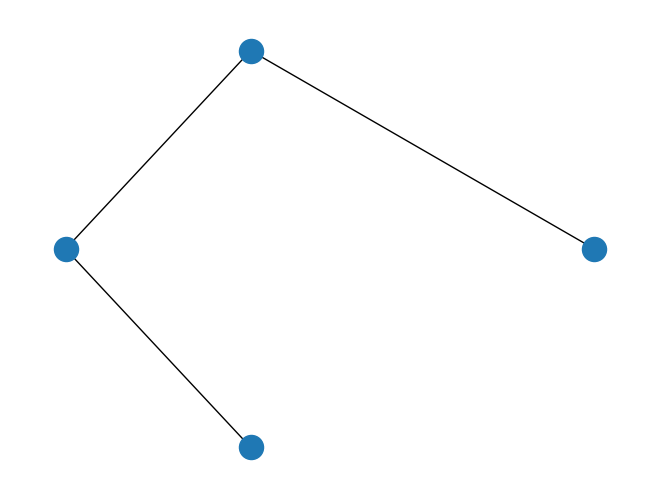

In [ ]:
# We can see our G is not a tree
print("G is Tree?:", nx.is_tree(G))

# We can however find a tree in G which spans all vertices provided G is
# connected (as in our case).
T = nx.minimum_spanning_tree(G)
nx.draw(T, pos=positions)

We say that two graphs are _isomorphic_ if there is a way to relabel their vertices such there is a 1-1 correspondence between their edges. One can create isomorphic graphs easily by acting with a permutation upon the vertices of one, but in general telling if two graphs are isomorphic is [hard](https://www.appstate.edu/~hirstjl/Turing/5pm3_Shor.pdf). One can construct [incomplete heuristics](https://en.wikipedia.org/wiki/Weisfeiler_Leman_graph_isomorphism_test) which are particularly relevant for GNNs.

In [ ]:
# We check that the two subgraph generated by deleting vertex 0 and 3 are
# isomorphic.
nx.is_isomorphic(Hs[0], Hs[3])

True

## Weightings

In our present example, entires of the adjacency matrix were a count of edges in a Multigraph. In this perspective, all edges are created equal.

In practice one may wish to have varying _weights_ for edges, which could model

*   resistivity in an electric circuit (electrical engineering)
*   travel time along a route (logistics)
*   proximity (when modelling DNA)

and much more.


To create such simple graphs with weighted edges we can just replace the values in the adjacency matrix with the weights of the edges.

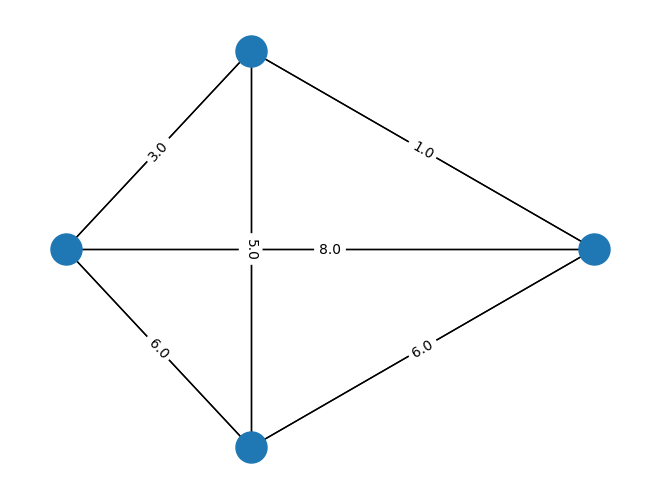

In [ ]:
# Construct the graph.
# We will construct using a weighted adjacency matrix.
# For simplicity I will perturb the previous one with some noise, then we treat
# the created graph not as a MultiGraph but simply a Graph.
adj_array = np.array([[0., 2., 1., 0.],
                      [2., 0., 1., 2.],
                      [1., 1., 0., 1.],
                      [0., 2., 1., 0.]])
noise = np.random.rand(4, 4)
noise = noise - np.transpose(noise)
noise = np.round(np.abs(noise), 1)
adj_array += 10*noise
G = nx.from_numpy_array(adj_array,
                        create_using=nx.Graph,
                        parallel_edges=False)

# Draw the graph.
edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw(G, pos=positions, node_size=500)
nx.draw_networkx_edges(
    G, pos=positions)
nx.draw_networkx_edge_labels(
    G, pos=positions, edge_labels=edge_labels)
plt.show()

Now we have a definition for _weighted degree_, which sums the weights of each incident edge to a vertex.

In [ ]:
G.degree, G.degree(weight='weight')

(DegreeView({0: 3, 1: 3, 2: 3, 3: 3}),
 DegreeView({0: 3.9, 1: 5.6, 2: 4.2, 3: 4.3}))

One can construct the weight of the shortest path between to vertices using the weighted adjacency matrix and now the [_tropical exponent_](https://personalpages.manchester.ac.uk/staff/mark.muldoon/Teaching/DiscreteMaths/LectureNotes/TropicalShortestPaths.pdf) $A^{\otimes l}$.


The more standard approach would be to use [Dijkstra's algorithm](https://networkx.org/documentation/stable/reference/algorithms/shortest_paths/dijkstra.html).

In [ ]:
# Depending on how the randomness has gone in the graph above, you may see that
# the shorted route is not always the direct one.
distances = nx.single_source_dijkstra_path_length(G, source=1)
distances

{1: 0, 0: 3.0, 2: 4.0, 3: 6.0}

# Appendix: research connection to graph theory

Based on the listed research interests on the [Imperial I‑X Centre for AI in Science people page](https://www.imperial.ac.uk/ix-ai-in-science/people/?utm_source=chatgpt.com), graph theory appears in different ways: directly (e.g. graph neural networks), implicitly through networked systems, or only weakly/not obviously at all. The grouping below is inferred from their stated expertise, not from full publication histories. ([Imperial College London][1])

## 1. Direct use of graph theory / graph machine learning

These researchers explicitly work on graph-based methods or domains where graph structures are central.

* Sophia Yaliraki — “Graph Learning”; molecular graphs, chemical interaction networks, allosteric pathways.
* Kristofer Linton-Reid — “Graph Neural Networks”; multiomics data integration via biological graphs.
* Samuel Hillman — “Graph Neural Networks”; materials and molecular structure prediction.
* Dan Akarca — network neuroscience; developing neural networks are naturally graph-structured.
* Marcus Ghosh — neural network architectures and neuroevolution; computational graphs and connectivity structures.
* Manolo Perez — phylogenetics uses tree/graph structures extensively.

## 2. Strong implicit graph-theoretic relevance (networks, interactions, relational systems)

These areas naturally rely on graphs even though “graph theory” is not explicitly stated.

### Biological and epidemiological networks

* Nick Jones — statistical genetics, stochastic processes, single-cell interactions.
* Andreas Joergensen — agent-based biological systems; interaction graphs.
* Calum Gabbutt — cancer evolution and clonal dynamics; evolutionary trees and lineage graphs.
* Margherita Molaro — epidemiology and agent-based simulations; contact networks.
* Maximilian Strobl — eco-evolutionary dynamics and spatial interactions.
* Anubhab Khan — population genetics and evolution; phylogenetic and ancestry graphs.
* Mariana Severo Ramundo — immuno-epidemiology; disease transmission networks.

### Physics / chemistry / materials with interaction graphs

* Austin Mroz — computational chemistry; molecules represented as graphs.
* Emma Wolpert — crystal structure prediction and coarse graining; lattice/interatomic graphs.
* Mohammed Azzouzi — materials discovery and computational chemistry.
* Kasper Tolborg — computational chemistry and energy materials.
* Xinwei Wang — crystal defects and materials structure networks.
* David Danaci — process optimization often uses network-flow/process graphs.
* Lucas Cornetta — electronic structure interactions can be represented graphically.

### AI / ML systems where graph structures may arise

* Ben Moseley — scientific ML in geophysics and planetary systems; spatial graphs/meshes.
* Benedikt Maier — anomaly detection in high-dimensional relational data.
* Laura Helleckes — Bayesian optimization over interconnected experimental systems.
* Lloyd Fung — symbolic model discovery and digital twinning; system graphs.
* Mikael Mieskolainen — high-energy physics event structures often map naturally to graphs.
* Paterne Gahungu — stochastic processes on interacting systems.
* Claire Heaney — urban airflow modelling can involve spatial graph discretizations.

## 3. Geometric / topological / combinatorial adjacency to graph theory

These researchers work in mathematics or geometry closely related to graph-theoretic ideas, though not necessarily on graphs directly.

* Daniel Platt — differential geometry and geometric analysis.
* Elli Heyes — geometry and string theory.
* Linden Disney Hogg — computational algebraic geometry.
* Sara Veneziale — computational geometry and AI for pure mathematics.
* Salvatore Mercuri — formal mathematics and theorem proving may involve combinatorial graph search.

## 4. Little or no obvious graph-theoretic connection from listed interests

Their listed expertise does not strongly suggest graph-theoretic methods from the short bios alone.

* Aidan Crilly
* Anjana Badrinarayanan
* Claire Baker
* Daniela Damasceno
* Irene Mendez Guerra
* Jingdong Zhang
* Jonathon Langford
* Kilian Stenning
* Ofosua Adi-Dako
* Uswah Khairuddin
* Benjamin Moss
* Fan Zhang
* Gema Vera-Gonzalez
* Nacime Bouziani
* Pranav Mamidanna
* Xiancheng Yu
* Zhenzhu Li

A useful high-level summary is:

* **Explicit graph theory / graph ML:** Yaliraki, Linton-Reid, Hillman, Akarca.
* **Network-science adjacent:** Jones, Molaro, Khan, Gabbutt, Strobl, Perez, etc.
* **Geometry/combinatorics adjacent:** Platt, Heyes, Veneziale, Disney Hogg.
* **Primarily non-graph-centric from the public descriptions:** the remaining researchers. ([Imperial College London][1])

[1]: https://www.imperial.ac.uk/ix-ai-in-science/people/?utm_source=chatgpt.com "Our people | Research groups | Imperial College London"
